# Online Retail (Superstore) Project — D7054E
Sales regression, customer churn classification, and customer segmentation.


## 1. Import Libraries

In [74]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from scipy.stats import pearsonr, f_oneway
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression, SGDRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, silhouette_score,
)

sns.set_palette("colorblind")  # colorblind-safe by design
sns.set_style("whitegrid")

# All results (tables + figures) get saved here so they can be
# reviewed later without re-running the whole notebook.
os.makedirs("outputs", exist_ok=True)

## 2. Load the Data
This is the only class in the whole notebook — just like the reference project, used only for loading. Everything after this is plain, sequential code.

In [75]:
class DataLoader:
    """Downloads the Superstore dataset from Kaggle."""

    def __init__(self):
        self.kaggle_dataset = "vivek468/superstore-dataset-final"

    def load(self):
        path = kagglehub.dataset_download(self.kaggle_dataset)
        csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]
        df = pd.read_csv(os.path.join(path, csv_file), encoding="latin1")
        return df


loader = DataLoader()
df = loader.load()
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 3. Data Cleaning & Formatting

### 3.1 Structure and Data Types

In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

### 3.2 Shape and Summary Statistics

In [77]:
print("Shape:", df.shape)
summary_stats = df.describe()
summary_stats.to_csv("outputs/summary_statistics.csv")
summary_stats

Shape: (9994, 21)


,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


### 3.3 Tidy Column Names, Parse Dates, Remove Duplicates
Raw columns like `"Order Date"` are renamed to `order_date` for consistency. Dates are converted from text to real `datetime` values so date arithmetic (needed later for recency) works correctly. One known duplicate row is removed.

In [78]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])
df = df.drop_duplicates()
df.head()

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,postal_code,region,product_id,category,sub-category,product_name,sales,quantity,discount,profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 4. Remove Identifier Columns and Split Feature Types
Identifier columns are dropped — they uniquely label a row rather than describing it, so keeping them would let a model "cheat" by memorizing rows instead of learning patterns.

In [79]:
id_columns = ["row_id", "order_id", "customer_id", "customer_name", "product_id", "product_name"]
df_features = df.drop(columns=id_columns)

categorical_cols = df_features.select_dtypes(include="object").columns.tolist()
numerical_cols = df_features.select_dtypes(include=np.number).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

Categorical columns: ['ship_mode', 'segment', 'country', 'city', 'state', 'region', 'category', 'sub-category']
Numerical columns: ['postal_code', 'sales', 'quantity', 'discount', 'profit']


## 5. Correlation Analysis
`RdBu_r` is used instead of a red-green scale, since red-green is the most common form of color blindness — red-blue stays distinguishable.

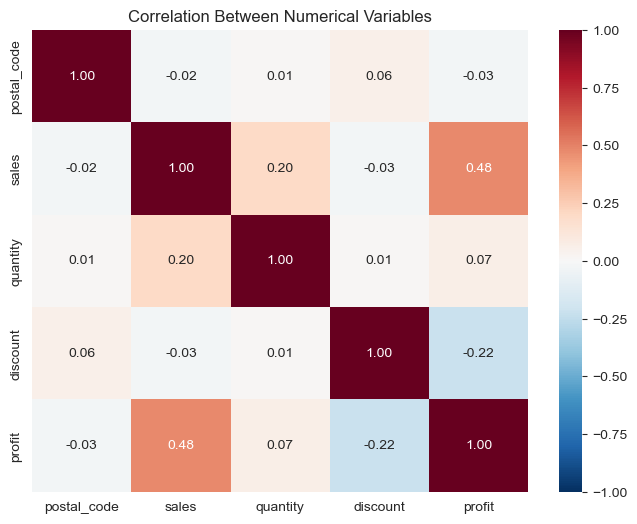

In [80]:
corr = df_features[numerical_cols].corr()
corr.to_csv("outputs/correlation_matrix.csv")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Numerical Variables")
plt.savefig("outputs/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Observation:
Looking at the correlation heatmap, the strongest relationship is between sales and profit (0.48), which makes intuitive sense, bigger orders should generally bring in more profit. What I found more interesting was that discount and profit are negatively correlated (-0.22). It's not a huge number, but it lines up with what I'd expect: giving bigger discounts eats into profit. I was a little surprised that quantity and sales are only weakly correlated (0.20). I expected buying more items to matter more for the total sale amount than it apparently does. postal_code correlating with basically nothing makes sense since it's just a location code, not a real number.

## 6. Analyzing Categorical and Continuous Variables

### 6.1 Categorical Variables

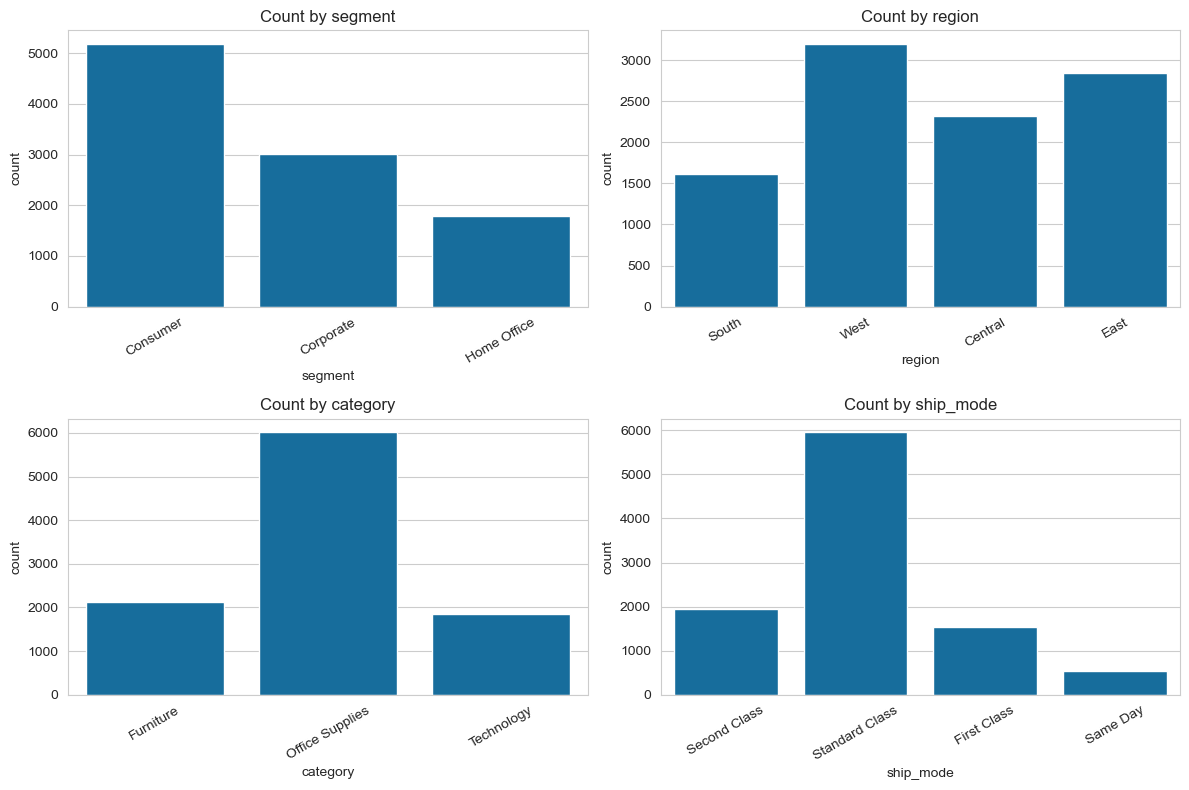

In [81]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ["segment", "region", "category", "ship_mode"]):
    sns.countplot(data=df_features, x=col, ax=ax)
    ax.set_title(f"Count by {col}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("outputs/categorical_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## Observation:
These plots show my dataset isn't very balanced across categories. Most orders are Office Supplies, and most customers are in the Consumer segment. Furniture and Technology, and the Corporate/Home Office segments, are much smaller by comparison. Same with ship_mode: almost everyone uses Standard Class, and Same Day shipping is barely used at all. I think this is worth keeping in mind for later, any result I get for a small category (like Same Day shipping) probably isn't as reliable as a result for a big one, since there's less data to learn from.

### 6.2 Continuous Variables

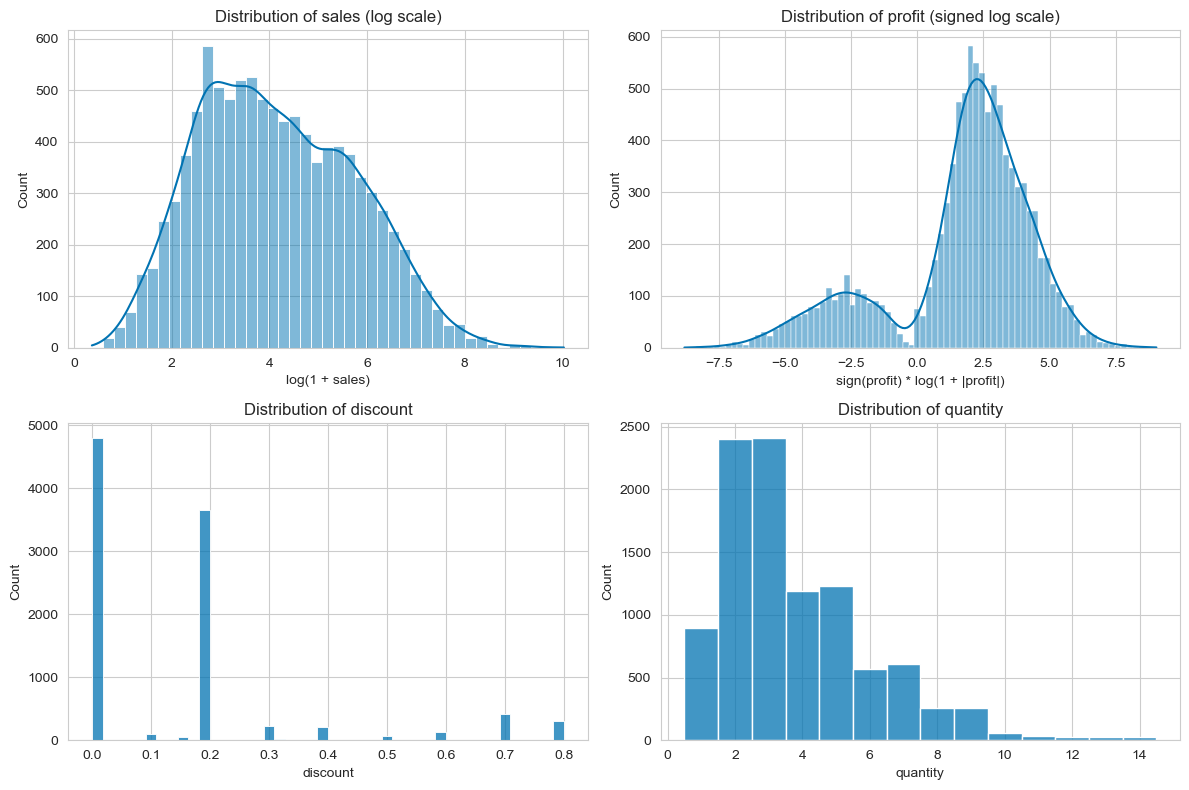

In [82]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# sales/profit are extremely right-skewed (a handful of orders reach
# 20,000+), so a log transform reveals the actual shape instead of one
# tall spike. log1p (log(1+x)) avoids log(0) issues since sales can be 0.
sns.histplot(np.log1p(df_features["sales"]), kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of sales (log scale)")
axes[0, 0].set_xlabel("log(1 + sales)")

# profit can be negative, so a plain log doesn't work. sign(x)*log1p(|x|)
# is a standard "signed log" transform — it compresses large values on
# both sides while keeping the sign (loss vs. profit) intact.
sns.histplot(
    np.sign(df_features["profit"]) * np.log1p(df_features["profit"].abs()),
    kde=True, ax=axes[0, 1]
)
axes[0, 1].set_title("Distribution of profit (signed log scale)")
axes[0, 1].set_xlabel("sign(profit) * log(1 + |profit|)")

# discount and quantity are discrete, not continuous — a KDE line
# smooths over gaps between values that can't actually occur (e.g. a
# quantity of 2.5), producing the wavy artifact from before.
sns.histplot(df_features["discount"], kde=False, ax=axes[1, 0])
axes[1, 0].set_title("Distribution of discount")

sns.histplot(df_features["quantity"], kde=False, discrete=True, ax=axes[1, 1])
axes[1, 1].set_title("Distribution of quantity")

plt.tight_layout()
plt.savefig("outputs/continuous_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## Observation:
My first attempt at these plots (with a normal histogram) was hard to read since sales and profit are so skewed, a few really large orders were making everything else look flat. After switching to a log scale, I could actually see the shape of the data. What stood out to me is that profit looks bimodal, there are two separate humps, one around a small loss and one around a moderate profit, rather than everything just spread around zero. That's a pattern I wouldn't have caught without transforming the data, and it makes me think discounting is creating two different "types" of orders rather than just adding random noise to profit.

## 7. Hypothesis Testing
**Hypothesis 1:** higher discount is associated with lower profit (Pearson correlation).

**Hypothesis 2:** average profit differs across product categories (ANOVA — used instead of a t-test because there are 3 groups, not 2).

In [83]:
corr_discount_profit, p_value_discount_profit = pearsonr(df["discount"], df["profit"])
print(f"Discount vs Profit: correlation = {corr_discount_profit:.3f}, p-value = {p_value_discount_profit:.3e}")

Discount vs Profit: correlation = -0.219, p-value = 2.702e-109


In [84]:
groups = [g["profit"].values for _, g in df.groupby("category")]
f_stat_category, p_value_category = f_oneway(*groups)
print(f"Profit by Category: F-statistic = {f_stat_category:.3f}, p-value = {p_value_category:.3e}")

Profit by Category: F-statistic = 54.311, p-value = 3.470e-24


In [86]:
hypothesis_results = pd.DataFrame([
    {"hypothesis": "discount vs profit", "statistic": corr_discount_profit,
     "statistic_type": "pearson_r", "p_value": p_value_discount_profit},
    {"hypothesis": "profit by category", "statistic": f_stat_category,
     "statistic_type": "f_statistic", "p_value": p_value_category},
])
hypothesis_results.to_csv("outputs/hypothesis_test_results.csv", index=False)
hypothesis_results

,hypothesis,statistic,statistic_type,p_value
0,discount vs profit,-0.219487,pearson_r,2.702294e-109
1,profit by category,54.311023,f_statistic,3.469918e-24


## Observation:
Both of my hypotheses turned out to be statistically significant, with extremely small p-values. The discount-profit correlation was moderate (-0.22) but real, and profit really does differ across product categories. Because my sample size is fairly large (9,994 order lines), I have to keep in mind that even small effects can come out "statistically significant". So I shouldn't read too much into the strength of the relationship just because the p-value is tiny. The correlation number itself (-0.22) tells me more about how strong the effect actually is than the p-value does.

## 8. Feature Engineering
Collapses order-level rows into one row per customer: RFM features (Recency, Frequency, Monetary) plus a derived churn label.

Recency is measured from one day after the dataset's last order (not today's real date), since this is historical data. A customer is labeled "churned" if their last order is more than `churn_window_days` before that reference date — a proxy label, not a certainty.

In [87]:
def build_customer_features(df, churn_window_days=180):
    reference_date = df["order_date"].max() + pd.Timedelta(days=1)

    customer_df = (
        df.groupby("customer_id")
        .agg(
            recency=("order_date", lambda dates: (reference_date - dates.max()).days),
            frequency=("order_id", "nunique"),
            monetary=("sales", "sum"),
        )
        .reset_index()
    )
    customer_df["avg_order_value"] = customer_df["monetary"] / customer_df["frequency"]
    customer_df["churned"] = (customer_df["recency"] > churn_window_days).astype(int)
    return customer_df


customer_df = build_customer_features(df, churn_window_days=180)
customer_df.to_csv("outputs/customer_features.csv", index=False)
customer_df.head()

,customer_id,recency,frequency,monetary,avg_order_value,churned
0,AA-10315,185,5,5563.560,1112.712000,1
1,AA-10375,20,9,1056.390,117.376667,0
2,AA-10480,260,4,1790.512,447.628000,1
3,AA-10645,56,6,5086.935,847.822500,0
4,AB-10015,416,3,886.156,295.385333,1


In [89]:
customer_df["churned"].value_counts(normalize=True)

churned
0    0.745271
1    0.254729
Name: proportion, dtype: float64

## 9. Modeling — Sales Regression

### 9.1 Prepare Data (Train/Test Split & Scaling)

In [90]:
feature_cols = ["quantity", "discount", "category", "sub-category", "region", "segment"]
X = pd.get_dummies(df[feature_cols], drop_first=True)
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling doesn't change Linear Regression's or Random Forest's predictions,
# but SGD Regressor needs it to converge properly — so we scale for all four
# models to keep every model's input identical.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9.2 Train Models: Linear Regression, SGD Regressor, Random Forest, Gradient Boosting

In [91]:
regression_models = {
    "Linear Regression": LinearRegression(),
    "SGD Regressor": SGDRegressor(random_state=42, max_iter=2000, tol=1e-3),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, random_state=42),
}

for name, model in regression_models.items():
    model.fit(X_train_scaled, y_train)

### 9.3 Compare Models

In [92]:
regression_results = []
for name, model in regression_models.items():
    preds = model.predict(X_test_scaled)
    regression_results.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, preds),
        "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "R2": r2_score(y_test, preds),
    })

regression_results_df = pd.DataFrame(regression_results)
regression_results_df.to_csv("outputs/regression_results.csv", index=False)
regression_results_df

,model,MAE,RMSE,R2
0,Linear Regression,226.320562,693.276025,0.186334
1,SGD Regressor,227.375534,699.826515,0.170886
2,Random Forest,211.376142,689.990044,0.194029
3,Gradient Boosting,198.972623,673.637871,0.231778


### 9.4 Feature Importance

In [94]:
importances = regression_models["Random Forest"].feature_importances_
importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance": importances,
}).sort_values("importance", ascending=False).reset_index(drop=True)

importance_df.to_csv("outputs/feature_importance.csv", index=False)
importance_df

,feature,importance
0,quantity,0.293574
1,sub-category_Copiers,0.127939
2,discount,0.126025
3,segment_Corporate,0.061324
4,region_East,0.052667
5,segment_Home Office,0.051155
6,sub-category_Machines,0.050215
7,region_South,0.044972
8,category_Office Supplies,0.042679
9,region_West,0.037860


## Observation:
Gradient Boosting was the best of the four models, but even its R² (0.23) is fairly low, meaning my features can only explain a modest portion of why sales values vary. I think this makes sense once I looked at feature importance: quantity and discount matter, but a lot of what determines an order's price probably comes down to which exact product was bought, which I don't have as a feature (I only have category/sub-category, not the specific product). One thing that caught my attention was that sub-category_Copiers had unusually high importance compared to other sub-categories, it seems like copiers are priced very differently from everything else, so the model is using that sub-category almost like a shortcut for "this is a high-price item." I also noticed SGD Regressor actually did slightly worse than plain Linear Regression, which surprised me at first. I assumed a more "advanced" method would automatically be better, but that's not always true.

### 9.5 Visualize Results

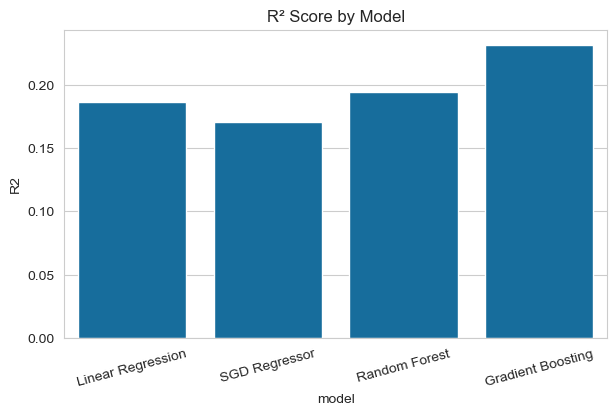

In [95]:
plt.figure(figsize=(7, 4))
sns.barplot(data=regression_results_df, x="model", y="R2")
plt.title("R² Score by Model")
plt.xticks(rotation=15)
plt.savefig("outputs/r2_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Observation:
This plot made the regression's weakness a lot clearer to me than the R² number alone did. Almost every prediction sits below the diagonal "perfect prediction" line, especially for the highest-value orders, the model is consistently underpredicting big sales. There's one order in particular (the most expensive one in the whole dataset) where the model predicted a fairly ordinary value even though the real sale was huge. That tells me the model is decent at predicting "typical" orders but has basically no way to catch rare, very large ones, since nothing in my features flags an order as unusual ahead of time.

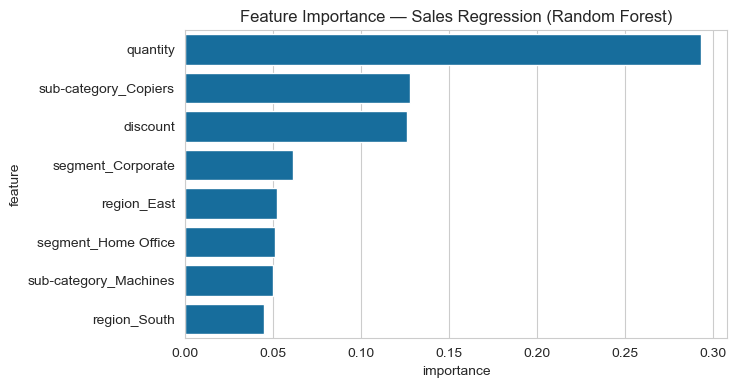

In [96]:
plt.figure(figsize=(7, 4))
sns.barplot(data=importance_df.head(8), x="importance", y="feature")
plt.title("Feature Importance — Sales Regression (Random Forest)")
plt.savefig("outputs/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

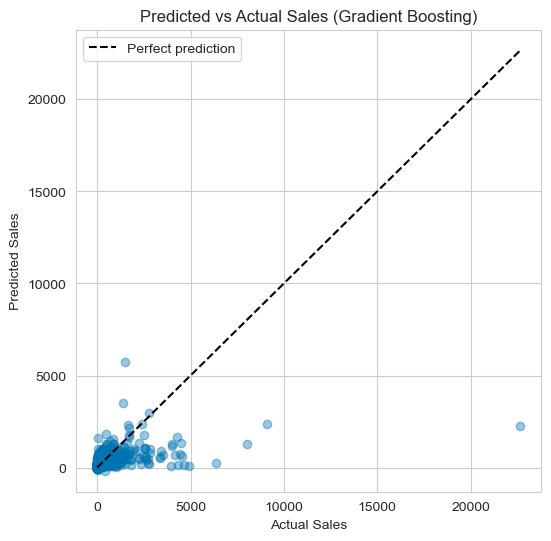

In [97]:
best_model_name = regression_results_df.sort_values("R2", ascending=False).iloc[0]["model"]
best_model = regression_models[best_model_name]
preds = best_model.predict(X_test_scaled)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, preds, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--", label="Perfect prediction")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title(f"Predicted vs Actual Sales ({best_model_name})")
plt.legend()
plt.savefig("outputs/predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Modeling — Customer Churn Classification

### 10.1 Prepare Data (Train/Test Split)

In [98]:
classification_feature_cols = ["recency", "frequency", "monetary", "avg_order_value"]
X_churn = customer_df[classification_feature_cols]
y_churn = customer_df["churned"]

# stratify=y_churn keeps the same churn ratio in both train and test sets —
# with an imbalanced target (~75/25 here), a plain random split risks leaving
# too few churned customers in the test set to evaluate reliably.
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_churn, y_churn, test_size=0.2, random_state=42, stratify=y_churn
)

### 10.2 Train Models: Logistic Regression, Random Forest

In [99]:
# class_weight="balanced" makes both models pay more attention to the
# minority (churned) class, instead of defaulting to "never churned" and
# still looking ~75% accurate while missing the class we actually care about.
classification_models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=42
    ),
}

for name, model in classification_models.items():
    model.fit(X_train_c, y_train_c)

### 10.3 Compare Models

In [101]:
classification_results = []
for name, model in classification_models.items():
    preds = model.predict(X_test_c)
    classification_results.append({
        "model": name,
        "accuracy": accuracy_score(y_test_c, preds),
        # precision/recall/F1 on the churned class specifically — accuracy
        # alone would hide whether the model actually finds churners.
        "precision": precision_score(y_test_c, preds),
        "recall": recall_score(y_test_c, preds),
        "f1": f1_score(y_test_c, preds),
    })

classification_results_df = pd.DataFrame(classification_results)
classification_results_df.to_csv("outputs/classification_results.csv", index=False)
classification_results_df

,model,accuracy,precision,recall,f1
0,Logistic Regression,0.993711,0.97619,1.0,0.987952
1,Random Forest,0.993711,0.97619,1.0,0.987952


### 10.4 Feature Importance

In [102]:
churn_importances = classification_models["Random Forest"].feature_importances_
churn_importance_df = pd.DataFrame({
    "feature": classification_feature_cols,
    "importance": churn_importances,
}).sort_values("importance", ascending=False).reset_index(drop=True)

churn_importance_df.to_csv("outputs/churn_feature_importance.csv", index=False)
churn_importance_df

,feature,importance
0,recency,0.920082
1,frequency,0.052219
2,monetary,0.017307
3,avg_order_value,0.010392


### 10.5 Visualize Results
**Note for the report:** `recency` is expected to dominate feature importance here, since `churned` was *defined from* `recency` in Section 8 — this is a form of definitional leakage worth stating explicitly, not a subtle pattern the model discovered.

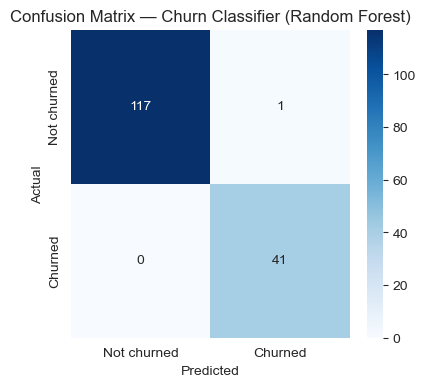

In [103]:
# Confusion matrix for the Random Forest model
cm = confusion_matrix(y_test_c, classification_models["Random Forest"].predict(X_test_c))

plt.figure(figsize=(4.5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Not churned", "Churned"], yticklabels=["Not churned", "Churned"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Churn Classifier (Random Forest)")
plt.savefig("outputs/churn_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

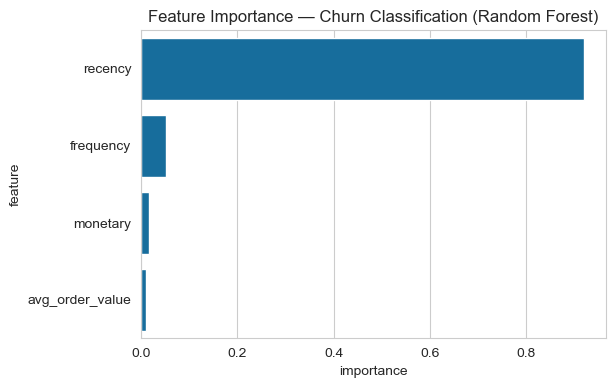

In [104]:
plt.figure(figsize=(6, 4))
sns.barplot(data=churn_importance_df, x="importance", y="feature")
plt.title("Feature Importance — Churn Classification (Random Forest)")
plt.savefig("outputs/churn_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## Observation:
At first glance, 99.4% accuracy and near-perfect precision/recall look really impressive. But when I looked at feature importance, recency alone accounted for 92% of the model's decisions, and then I remembered that I actually built the churned label using a 180-day recency cutoff in Section 8. So the model isn't really discovering some hidden pattern in customer behavior. it's mostly just re-learning the exact rule I used to create the label in the first place. I think this is an important limitation to be honest about rather than just reporting the high accuracy as if it were a genuine achievement.

## 11. Modeling — Customer Segmentation (Clustering)

### 11.1 Prepare Data (Scale RFM Features)
K-Means measures distance directly, so without scaling, `monetary` (in the thousands) would completely dominate over `recency`/`frequency` (tens-hundreds), making clusters reflect spend alone rather than genuine behavioral differences.

In [105]:
cluster_feature_cols = ["recency", "frequency", "monetary"]
scaler_cluster = StandardScaler()
X_scaled_cluster = scaler_cluster.fit_transform(customer_df[cluster_feature_cols])

### 11.2 Choose the Number of Clusters (Elbow Method)
Inertia (within-cluster sum of squares) naturally decreases as `k` increases; the "elbow" — where adding another cluster stops giving a big improvement — is a reasonable, defensible choice for `k`.

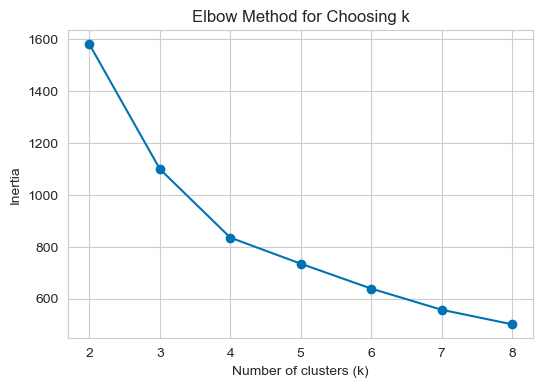

In [106]:
inertias = []
k_values = range(2, 9)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled_cluster)
    inertias.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Choosing k")
plt.savefig("outputs/elbow_plot.png", dpi=150, bbox_inches="tight")
plt.show()

### 11.3 Fit K-Means and Evaluate

In [107]:
chosen_k = 4  # picked from the elbow plot above — adjust if your elbow lands elsewhere

kmeans = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
customer_df["cluster"] = kmeans.fit_predict(X_scaled_cluster)

sil_score = silhouette_score(X_scaled_cluster, customer_df["cluster"])
print(f"Silhouette score (k={chosen_k}): {sil_score:.3f}")

Silhouette score (k=4): 0.355


### 11.4 Cluster Profiles
A cluster ID (0, 1, 2...) means nothing on its own — the average RFM values per cluster are what let you *name* the segments (e.g. "low recency, high frequency, high monetary" reads as "loyal, high-value customers").

In [108]:
cluster_profile = customer_df.groupby("cluster")[cluster_feature_cols].mean()
cluster_profile.to_csv("outputs/cluster_profiles.csv")
customer_df.to_csv("outputs/customer_features_with_clusters.csv", index=False)
cluster_profile

,recency,frequency,monetary
cluster,,,
0,72.741611,8.516779,3322.222985
1,101.197015,4.731343,1669.688290
2,123.718750,8.296875,9479.545687
3,559.489583,3.697917,1470.228226


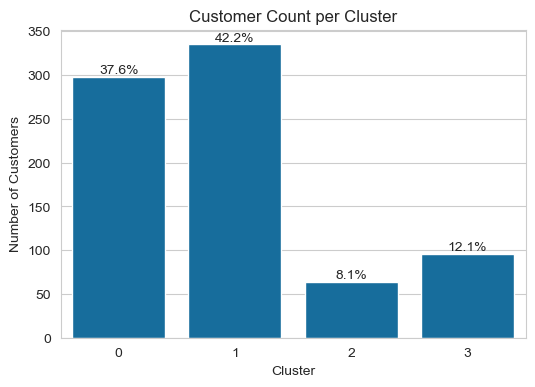

In [113]:
cluster_counts = customer_df["cluster"].value_counts().sort_index()
cluster_percentages = (cluster_counts / cluster_counts.sum() * 100).round(1)

plt.figure(figsize=(6, 4))
sns.barplot(x=cluster_counts.index, y=cluster_counts.values)
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.title("Customer Count per Cluster")
for i, (count, pct) in enumerate(zip(cluster_counts.values, cluster_percentages.values)):
    plt.text(i, count, f"{pct}%", ha="center", va="bottom")
plt.savefig("outputs/cluster_sizes.png", dpi=150, bbox_inches="tight")
plt.show()

## Observation:
This chart puts my cluster profiles into perspective in a way the averages table alone couldn't. My "VIP" cluster (Cluster 2), the one with by far the highest average spending ($9,480) only makes up 8.1% of my customer base. Meanwhile, the two largest groups (Clusters 0 and 1, together 79.8% of customers) spend far less per customer ($3,322 and $1,670 respectively). This is a pretty classic pattern in retail data: a small group of high-value customers versus a much larger group of moderate spenders. It makes me think that if this were a real business decision, treating "VIP" and "regular" customers the same way probably isn't optimal, but at the same time, since VIPs are less than 1 in 10 customers, a strategy that focuses only on them would be ignoring the vast majority of the customer base. I also notice that the "lapsed" group (Cluster 3, 12.1%) is larger than the VIP group, meaning I currently have more customers who've stopped buying than customers who are my biggest spenders, which feels like a meaningful thing for a business to know.

### 11.5 Visualize Results

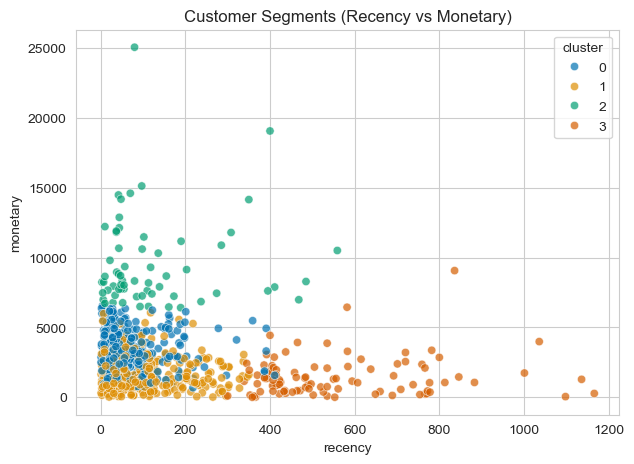

In [109]:
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=customer_df, x="recency", y="monetary",
    hue="cluster", palette="colorblind", alpha=0.7
)
plt.title("Customer Segments (Recency vs Monetary)")
plt.savefig("outputs/customer_segments.png", dpi=150, bbox_inches="tight")
plt.show()

## Observation:
The elbow plot didn't have one obvious sharp bend, it was more of a gradual curve, so choosing k=4 was a judgment call rather than an exact answer. Looking at the cluster profiles, though, the groups do make sense to me: one cluster is clearly my highest-spending customers, one looks like regular/loyal shoppers, one looks like occasional buyers, and one has a recency far higher than the rest, those look like customers who've basically stopped ordering. In the scatter plot, two of the clusters overlap a lot visually, but when I checked the actual cluster averages, they're separated by frequency, which isn't one of the two axes I plotted. That was a good reminder that a 2D plot can hide real differences that exist in a third dimension.

## 11.6 PCA Projection of Clusters

Variance explained by each component: [0.54766481 0.28598897]
Total variance captured by 2 components: 0.833653777296874


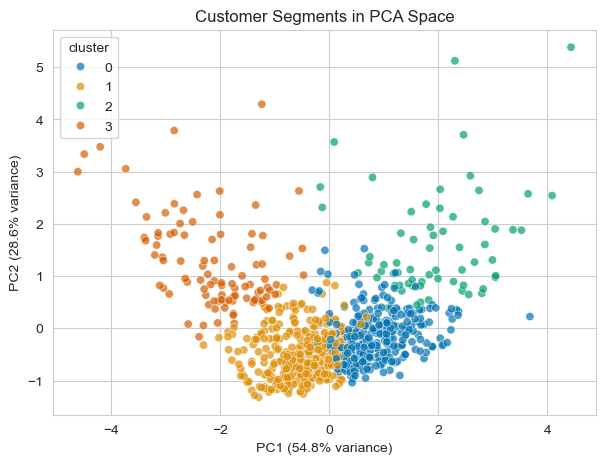

In [111]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_scaled_cluster)
customer_df["pca1"] = pca_coords[:, 0]
customer_df["pca2"] = pca_coords[:, 1]

print("Variance explained by each component:", pca.explained_variance_ratio_)
print("Total variance captured by 2 components:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(7, 5))
sns.scatterplot(data=customer_df, x="pca1", y="pca2", hue="cluster", palette="colorblind", alpha=0.7)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("Customer Segments in PCA Space")
plt.savefig("outputs/customer_segments_pca.png", dpi=150, bbox_inches="tight")
plt.show()

## Observation:
The PCA plot captured 83.4% of the total variance in just 2 components (54.8% + 28.6%), which I think is high enough that I can trust this as a fair simplified view of my 3-feature data. Clusters 2 (green) and 3 (orange) separate out the most clearly, sitting almost at opposite ends of the plot, which lines up with them being my most opposite groups in the original table (highest monetary value vs. highest recency). Clusters 0 (blue) and 1 (yellow) are still somewhat close together, but now they're mainly separated vertically along PC2 rather than being fully mixed, which is an improvement over my very first scatter plot. I also noticed the shape of the point cloud is a bit skewed rather than forming four tight, obviously separate blobs that matches the moderate silhouette score (0.355) from earlier rather than contradicting it; if the plot showed four perfectly isolated clusters, I'd actually expect a much higher silhouette score than what I got.

## 11.7 Pairwise Feature Relationships (Pairplot)

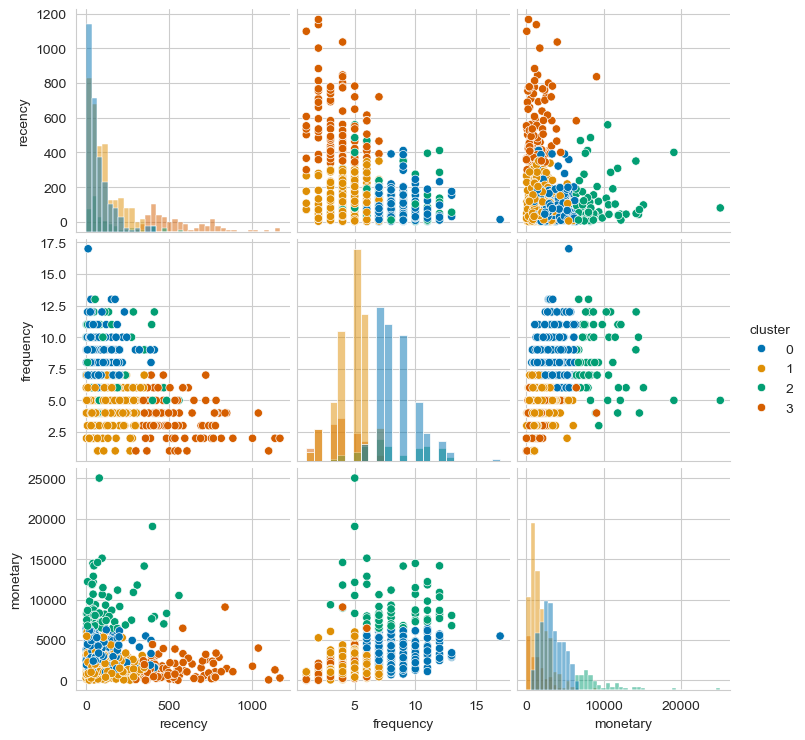

In [112]:
pairplot_fig = sns.pairplot(
    customer_df, vars=cluster_feature_cols, hue="cluster",
    palette="colorblind", diag_kind="hist"
)
pairplot_fig.savefig("outputs/customer_segments_pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

## Observation:
Looking at the pairplot, the panel that helped me the most was frequency vs. recency (middle-left). It shows clusters 0 (blue) and 1 (yellow) sitting in a similar recency range, but clearly split apart on the frequency axis, cluster 0 clusters around 7-12 purchases, while cluster 1 sits mostly at 2-5. That's the exact separation the earlier recency-vs-monetary scatter couldn't show, since it never displayed frequency at all. The recency vs. monetary panel (top-right) also makes cluster 3 (orange) stand out clearly. It's the only group stretching out toward very high recency values (500+ days), confirming these really are the "lapsed" customers. The diagonal histograms are useful too: the frequency histogram shows cluster 1 (yellow) piling up heavily around 3-5, while cluster 0 (blue) is shifted noticeably higher, which is a cleaner way to see the separation than trying to read it off a scatter.